In [1]:
!pip install pandas scikit-learn matplotlib seaborn nltk wordcloud

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

print("Libraries imported successfully!")

Libraries imported successfully!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [3]:
df = pd.read_csv(
    "/content/twitter_training.csv",
    header=None
)

df.columns = [
    "id", "entity", "sentiment", "text"
]

print("Dataset shape:", df.shape)
display(df.head())
print(df.info())
print(df["sentiment"].value_counts())

Dataset shape: (74682, 4)


,id,entity,sentiment,text
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         74682 non-null  int64 
 1   entity     74682 non-null  object
 2   sentiment  74682 non-null  object
 3   text       73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB
None
sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64


In [4]:
df = df.dropna(subset=["text", "sentiment"]).copy()

df["sentiment"] = (
    df["sentiment"].astype(str).str.strip().str.title()
)

# Remove irrelevant rows for a 3-class model
df = df[df["sentiment"].isin(
    ["Positive", "Negative", "Neutral"]
)].copy()

df["text"] = df["text"].astype(str)
df = df.drop_duplicates(subset=["text", "sentiment"])

print("Cleaned dataset:", df.shape)
print(df["sentiment"].value_counts())

Cleaned dataset: (57485, 4)
sentiment
Negative    21237
Positive    19138
Neutral     17110
Name: count, dtype: int64


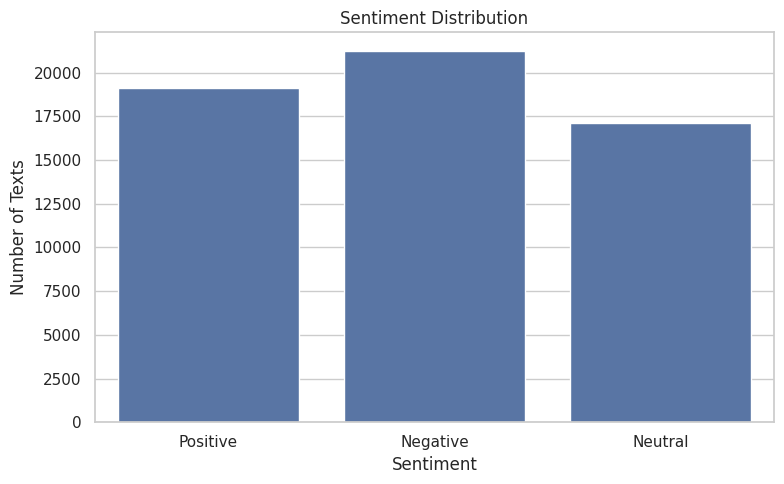

In [5]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="sentiment",
    order=["Positive", "Negative", "Neutral"]
)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Texts")
plt.tight_layout()
plt.show()

In [6]:
stop_words = set(stopwords.words("english"))
stop_words.discard("not")
stop_words.discard("no")
stop_words.discard("nor")

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = text.split()
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return " ".join(tokens)

df["clean_text"] = df["text"].apply(preprocess_text)

display(df[["text", "clean_text", "sentiment"]].head())

,text,clean_text,sentiment
0,im getting on borderlands and i will murder yo...,im getting borderlands murder,Positive
1,I am coming to the borders and I will kill you...,coming borders kill,Positive
2,im getting on borderlands and i will kill you ...,im getting borderlands kill,Positive
3,im coming on borderlands and i will murder you...,im coming borderlands murder,Positive
4,im getting on borderlands 2 and i will murder ...,im getting borderlands murder,Positive


TF-IDF (Term Frequency–Inverse Document Frequency) converts text into numerical features that machine learning models can process. It gives higher importance to words that are useful in individual documents and less importance to words that appear frequently across many documents. This helps classifiers learn patterns associated with positive, negative, and neutral sentiment.

In [7]:
X = df["clean_text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])
print("Testing samples:", X_test_tfidf.shape[0])
print("Number of features:", X_train_tfidf.shape[1])

Training samples: 45988
Testing samples: 11497
Number of features: 15000


In [8]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}

predictions = {}
results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print("\nMODEL:", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))


MODEL: Naive Bayes
Accuracy: 76.86 %
              precision    recall  f1-score   support

    Negative       0.75      0.86      0.80      4247
     Neutral       0.82      0.62      0.71      3422
    Positive       0.76      0.80      0.78      3828

    accuracy                           0.77     11497
   macro avg       0.78      0.76      0.76     11497
weighted avg       0.77      0.77      0.77     11497


MODEL: Logistic Regression
Accuracy: 82.42 %
              precision    recall  f1-score   support

    Negative       0.81      0.89      0.85      4247
     Neutral       0.84      0.75      0.79      3422
    Positive       0.83      0.82      0.82      3828

    accuracy                           0.82     11497
   macro avg       0.83      0.82      0.82     11497
weighted avg       0.82      0.82      0.82     11497



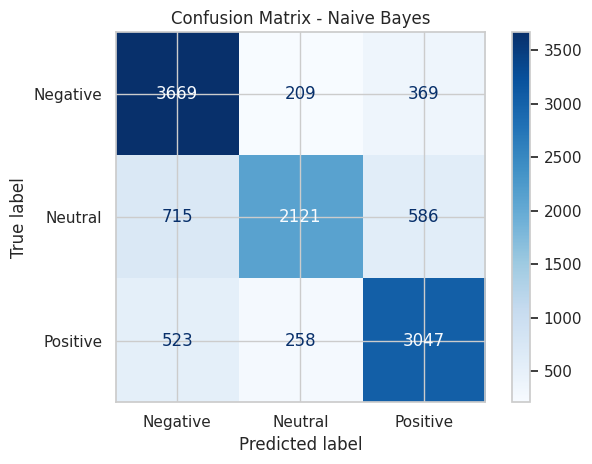

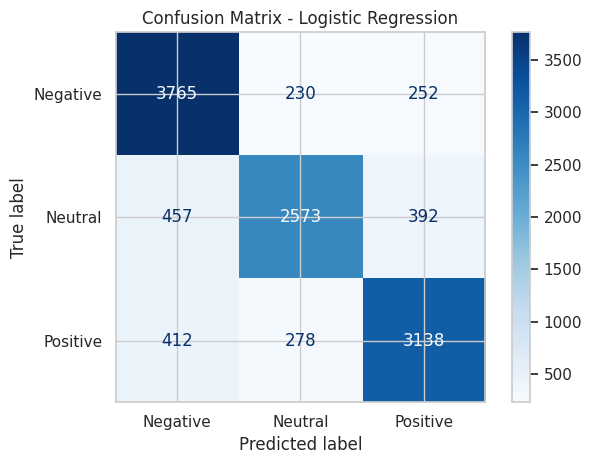

In [9]:
for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=["Negative", "Neutral", "Positive"]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Neutral", "Positive"]
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [10]:
results_df = pd.DataFrame(results)
results_df["Accuracy (%)"] = (
    results_df["Accuracy"] * 100
).round(2)

display(results_df[["Model", "Accuracy (%)"]])

best_model_name = results_df.loc[
    results_df["Accuracy"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Best model based on accuracy:", best_model_name)

,Model,Accuracy (%)
0,Naive Bayes,76.86
1,Logistic Regression,82.42


Best model based on accuracy: Logistic Regression


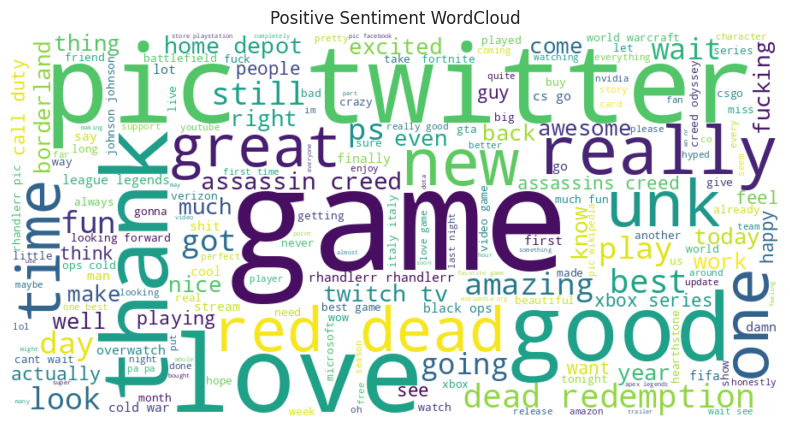

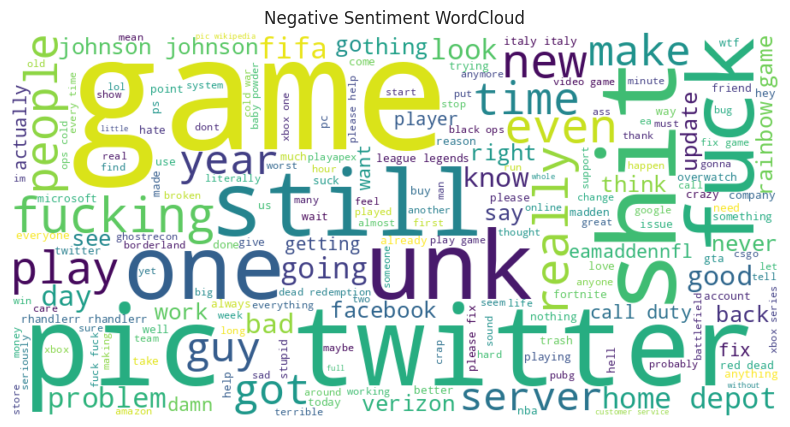

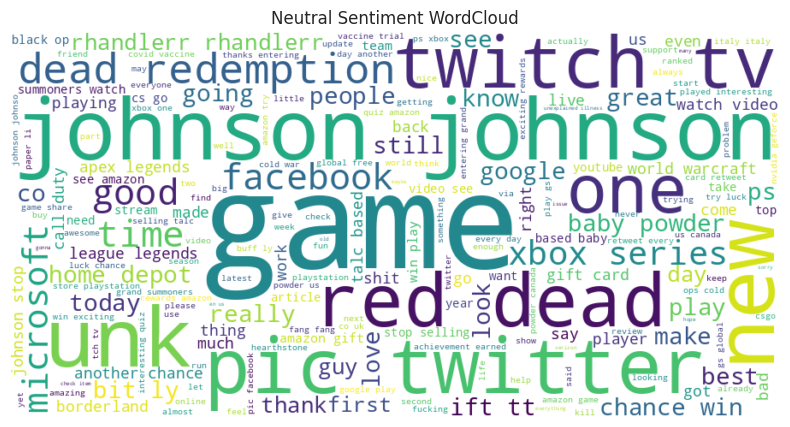

In [11]:
for sentiment in ["Positive", "Negative", "Neutral"]:
    text = " ".join(
        df.loc[df["sentiment"] == sentiment, "clean_text"]
    )

    if text.strip():
        wc = WordCloud(
            width=900,
            height=450,
            background_color="white"
        ).generate(text)

        plt.figure(figsize=(10, 5))
        plt.imshow(wc, interpolation="bilinear")
        plt.axis("off")
        plt.title(f"{sentiment} Sentiment WordCloud")
        plt.show()

In [12]:
best_predictions = predictions[best_model_name]

error_df = pd.DataFrame({
    "Text": X_test.values,
    "Actual": y_test.values,
    "Predicted": best_predictions
})

errors = error_df[
    error_df["Actual"] != error_df["Predicted"]
].head(5)

display(errors)

,Text,Actual,Predicted
3,obviously disrespectful coaches could see fiel...,Neutral,Negative
8,johnson johnson discontinues talc based powder...,Negative,Neutral
10,dont care whatever fucking retcon whatever sub...,Neutral,Negative
12,oh going blow snail chest fuck,Neutral,Negative
21,big news numerous great companies seeing fanta...,Neutral,Positive


In [13]:
def predict_sentiment(text):
    cleaned = preprocess_text(text)
    vector = tfidf.transform([cleaned])
    prediction = best_model.predict(vector)[0]

    print("Input:", text)
    print("Predicted sentiment:", prediction)

predict_sentiment("I really love this product!")
predict_sentiment("This is the worst experience ever.")
predict_sentiment("The product arrived today.")

Input: I really love this product!
Predicted sentiment: Positive
Input: This is the worst experience ever.
Predicted sentiment: Negative
Input: The product arrived today.
Predicted sentiment: Positive
